In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Copy the cube to Colab’s local disk

In [3]:
from pathlib import Path

!cp -r /content/drive/MyDrive/BEED_DATA/cube_monthly /content/cube_local
cube_dir = Path('/content/cube_local')
print(len(list(cube_dir.glob('*.npy'))), "files copied")

72 files copied


In [4]:
import numpy as np, pandas as pd, torch
from pathlib import Path
from torch.utils.data import Dataset

root = Path('/content/drive/MyDrive/BEED_DATA')
months = pd.period_range("2020-01", "2025-12", freq="M")

# use the local copy if you made one, otherwise read from Drive (slower)
cube_dir = Path('/content/cube_local') if Path('/content/cube_local').exists() else root/'cube_monthly'
print("cube folder:", cube_dir, "|", len(list(cube_dir.glob('*.npy'))), "files")

# ---- statistics from training years only (2020-2023) ----
train_months = [m for m in months if m.year <= 2023]
n_ch = 13
s = np.zeros(n_ch); ss = np.zeros(n_ch); n = np.zeros(n_ch)
for m in train_months:
    a = np.load(cube_dir/f"{m}.npy", mmap_mode='r')[:, ::4, ::4].astype('float32')
    f = np.isfinite(a); a0 = np.where(f, a, 0)
    s += a0.sum(axis=(1, 2)); ss += (a0**2).sum(axis=(1, 2)); n += f.sum(axis=(1, 2))
mean = (s / n).astype('float32')
std  = np.sqrt(ss / n - (s / n)**2).astype('float32') + 1e-6

weather = pd.read_csv(root/'weather_features.csv', index_col=0)
w_train = weather.loc[[str(m) for m in train_months]]
w_mean, w_std = w_train.mean().values, w_train.std().values + 1e-6
weather_vals = weather.values
spi = pd.read_csv(root/'labels.csv', index_col=0)['spi3_prov'].values
np.savez(root/'norm_stats.npz', mean=mean, std=std, w_mean=w_mean, w_std=w_std)

# ---- patch locations (64x64 at 90 m, at least half inside cropland) ----
mask90 = np.load(root/'mask90.npy')
P, STRIDE, T = 64, 32, 6
origins = [(r, c) for r in range(0, mask90.shape[0] - P + 1, STRIDE)
                  for c in range(0, mask90.shape[1] - P + 1, STRIDE)
           if mask90[r:r+P, c:c+P].mean() >= 0.5]
print(len(origins), "patches per month")

class BeedDataset(Dataset):
    def __init__(self, target_months, train=False, s2_dropout=0.2):
        self.t_idx = [months.get_loc(m) for m in target_months if months.get_loc(m) >= T - 1]
        self.train, self.p, self.cubes = train, s2_dropout, {}
    def _cube(self, i):
        if i not in self.cubes:
            self.cubes[i] = np.load(cube_dir/f"{months[i]}.npy", mmap_mode='r')
        return self.cubes[i]
    def __len__(self):
        return len(self.t_idx) * len(origins)
    def __getitem__(self, idx):
        t = self.t_idx[idx // len(origins)]
        r, c = origins[idx % len(origins)]
        x = np.stack([self._cube(i)[:, r:r+P, c:c+P].astype('float32')
                      for i in range(t - T + 1, t + 1)])            # (T, 13, P, P)
        x = (x - mean[None, :, None, None]) / std[None, :, None, None]
        v_s1 = np.isfinite(x[:, 0:1]); v_s2 = np.isfinite(x[:, 3:4])   # validity layers
        x = np.nan_to_num(x, nan=0.0)
        if self.train and np.random.rand() < self.p:                  # S2 dropout
            x[:, 3:] = 0; v_s2[:] = False
        x = np.concatenate([x, v_s1, v_s2], axis=1).astype('float32')  # (T, 15, P, P)
        w = ((weather_vals[t-T+1:t+1] - w_mean) / w_std).astype('float32')
        return torch.from_numpy(x), torch.from_numpy(w), torch.tensor(spi[t], dtype=torch.float32)

train_ds = BeedDataset([m for m in months if m.year <= 2023], train=True)
val_ds   = BeedDataset([m for m in months if m.year == 2024])
test_ds  = BeedDataset([m for m in months if m.year == 2025])
x, w, y = train_ds[0]
print(x.shape, w.shape, y)      # expect torch.Size([6, 15, 64, 64]) torch.Size([6, 13]) and an SPI value

cube folder: /content/cube_local | 72 files
1228 patches per month
torch.Size([6, 15, 64, 64]) torch.Size([6, 13]) tensor(1.7604)


## Run the model cell

This builds three versions so you can compare them, as your diagram’s “baseline” step asks:

weather_only: the baseline, with no satellite data.
late: S1 branch, S2 branch and weather branch, joined at the end.
attention: the same branches, but a learned weighting picks which source to trust. It switches Sentinel-2 off automatically when a window has no optical data.

In [5]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, RandomSampler, Subset

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)          # switch Runtime > Change runtime type > GPU if this says cpu

S1_CH = [0, 1, 2, 13]                            # VV, VH, VV-VH, S1 validity
S2_CH = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14]    # 6 bands, 4 indices, S2 validity

class Branch(nn.Module):
    def __init__(self, c_in, hid=64):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(c_in, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.rnn = nn.LSTM(64, hid, batch_first=True)
    def forward(self, x):                        # (B, T, C, P, P)
        B, T = x.shape[:2]
        f = self.cnn(x.flatten(0, 1)).flatten(1).view(B, T, -1)
        return self.rnn(f)[1][0][-1]             # (B, hid)

class FusionNet(nn.Module):
    def __init__(self, mode="attention", hid=64):
        super().__init__()
        self.mode = mode
        self.s1 = Branch(len(S1_CH), hid)
        self.s2 = Branch(len(S2_CH), hid)
        self.w = nn.GRU(13, hid, batch_first=True)
        self.score = nn.Linear(hid, 1)
        d_in = {"weather_only": hid, "late": 3 * hid, "attention": hid}[mode]
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(d_in, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x, w):
        hw = self.w(w)[1][-1]
        if self.mode == "weather_only":
            return self.head(hw)
        h1 = self.s1(x[:, :, S1_CH]); h2 = self.s2(x[:, :, S2_CH])
        s2_ok = (x[:, :, 14].mean(dim=(1, 2, 3)) > 0).float()      # 0 = no S2 in this window
        if self.mode == "late":
            return self.head(torch.cat([h1, h2 * s2_ok[:, None], hw], dim=1))
        H = torch.stack([h1, h2, hw], dim=1)                       # (B, 3, hid)
        sc = self.score(torch.tanh(H)).squeeze(-1)                 # (B, 3)
        sc = torch.cat([sc[:, :1],
                        sc[:, 1:2].masked_fill(s2_ok[:, None] == 0, -1e9),
                        sc[:, 2:]], dim=1)
        a = torch.softmax(sc, dim=1)
        return self.head((a.unsqueeze(-1) * H).sum(1))

def evaluate(model, ds, n_patch=48):
    """District-level prediction per month = mean over n_patch patches."""
    model.eval()
    sel = np.linspace(0, len(origins) - 1, n_patch).astype(int)
    idx = [k * len(origins) + j for k in range(len(ds.t_idx)) for j in sel]
    dl = DataLoader(Subset(ds, idx), batch_size=32, num_workers=2)
    out = []
    with torch.no_grad():
        for x, w, y in dl:
            out.append(model(x.to(dev), w.to(dev)).squeeze(1).cpu())
    p = torch.cat(out).view(len(ds.t_idx), n_patch).mean(1).numpy()
    y = np.array([spi[t] for t in ds.t_idx])
    return dict(rmse=float(np.sqrt(((p - y) ** 2).mean())),
                mae=float(np.abs(p - y).mean()),
                r=float(np.corrcoef(p, y)[0, 1])), p, y

def train(mode, epochs=2, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    model = FusionNet(mode).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    dl = DataLoader(train_ds, batch_size=32, num_workers=2,
                    sampler=RandomSampler(train_ds, replacement=False, num_samples=1600))
    for ep in range(epochs):
        model.train(); tot = n = 0
        for x, w, y in dl:
            x, w, y = x.to(dev), w.to(dev), y.to(dev)
            loss = F.mse_loss(model(x, w).squeeze(1), y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(y); n += len(y)
        m, _, _ = evaluate(model, val_ds)
        print(mode, "epoch", ep, "| train mse", round(tot / n, 3),
              "| val", {k: round(v, 3) for k, v in m.items()})
    return model

# reference: always predicting the training-period average
y_tr = np.array([spi[t] for t in train_ds.t_idx])
y_va = np.array([spi[t] for t in val_ds.t_idx])
print("constant-mean baseline, val RMSE:", round(float(np.sqrt(((y_va - y_tr.mean()) ** 2).mean())), 3))

model_test = train("attention", epochs=2)       # first run: just check it works and see the speed

device: cuda
constant-mean baseline, val RMSE: 1.14
attention epoch 0 | train mse 1.201 | val {'rmse': 1.145, 'mae': 0.779, 'r': -0.27}
attention epoch 1 | train mse 0.915 | val {'rmse': 1.336, 'mae': 0.886, 'r': -0.345}


  weather_only seed 0 epoch  0 | val rmse 1.392 r -0.24
  weather_only seed 0 epoch  1 | val rmse 1.728 r -0.32
  weather_only seed 0 epoch  2 | val rmse 1.871 r -0.35
  weather_only seed 0 epoch  3 | val rmse 1.815 r -0.37
  weather_only seed 0 epoch  4 | val rmse 1.742 r -0.39
  weather_only seed 0 epoch  5 | val rmse 1.737 r -0.39
  weather_only seed 0 epoch  6 | val rmse 1.726 r -0.45
weather_only finished in 106s

  late seed 0 epoch  0 | val rmse 1.432 r -0.20
  late seed 0 epoch  1 | val rmse 1.843 r -0.33
  late seed 0 epoch  2 | val rmse 1.949 r -0.37
  late seed 0 epoch  3 | val rmse 1.784 r -0.30
  late seed 0 epoch  4 | val rmse 1.717 r -0.30
  late seed 0 epoch  5 | val rmse 1.758 r -0.36
  late seed 0 epoch  6 | val rmse 1.745 r -0.33
late finished in 111s

  attention seed 0 epoch  0 | val rmse 1.378 r -0.29
  attention seed 0 epoch  1 | val rmse 1.604 r -0.32
  attention seed 0 epoch  2 | val rmse 1.922 r -0.33
  attention seed 0 epoch  3 | val rmse 1.846 r -0.36
  atte

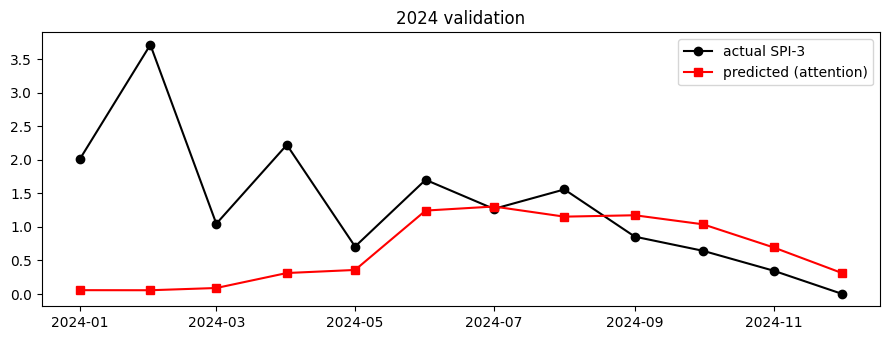

confusion matrix (rows actual, columns predicted; 0 dry, 1 normal, 2 wet):
[[0 0 0]
 [0 3 2]
 [0 4 3]]


In [7]:
import time, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

spi = pd.read_csv(root/'labels_v2.csv', index_col=0)['spi3_long'].values

# ---------- metrics ----------
def spi_class(v):                       # 0 = dry, 1 = near normal, 2 = wet
    return np.where(v <= -1.0, 0, np.where(v >= 1.0, 2, 1))

def metrics(p, y):
    yc, pc = spi_class(y), spi_class(p)
    with np.errstate(all='ignore'):
        r = np.corrcoef(p, y)[0, 1]
    return dict(rmse=np.sqrt(((p - y) ** 2).mean()), mae=np.abs(p - y).mean(), r=r,
                r2=1 - ((p - y) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                acc=accuracy_score(yc, pc),
                f1_macro=f1_score(yc, pc, average='macro', labels=np.unique(yc), zero_division=0))

def baselines(t_list):
    y = np.array([spi[t] for t in t_list])
    tr = train_ds.t_idx
    clim = {m: np.mean([spi[t] for t in tr if months[t].month == m]) for m in range(1, 13)}
    return y, {
        "const_mean":  np.full(len(y), np.mean([spi[t] for t in tr])),
        "month_clim":  np.array([clim[months[t].month] for t in t_list]),
        "persistence": np.array([spi[t - 1] for t in t_list]),
    }

# ---------- better training ----------
def train2(mode, epochs=25, patience=6, seed=0, n_samples=2400, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    model = FusionNet(mode).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    dl = DataLoader(train_ds, batch_size=32, num_workers=2,
                    sampler=RandomSampler(train_ds, replacement=False, num_samples=n_samples))
    best, best_state, bad = 1e9, None, 0
    for ep in range(epochs):
        model.train()
        for x, w, y in dl:
            x, w, y = x.to(dev), w.to(dev), y.to(dev)
            if np.random.rand() < 0.5: x = torch.flip(x, dims=[-1])
            if np.random.rand() < 0.5: x = torch.flip(x, dims=[-2])
            loss = F.huber_loss(model(x, w).squeeze(1), y, delta=1.0)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        sched.step()
        m, _, _ = evaluate(model, val_ds)
        print(f"  {mode} seed {seed} epoch {ep:2d} | val rmse {m['rmse']:.3f} r {m['r']:.2f}")
        if m['rmse'] < best - 1e-3:
            best, bad = m['rmse'], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model

# ---------- run ----------
SEEDS = [0]          # first run with one seed to check the time; then use [0, 1, 2]
y_val, base_val = baselines(val_ds.t_idx)
rows, preds_val = {}, {}
for name, p in base_val.items():
    rows[name] = metrics(p, y_val)

for mode in ["weather_only", "late", "attention"]:
    t0 = time.time(); ps = []
    for s in SEEDS:
        m = train2(mode, seed=s)
        torch.save(m.state_dict(), root/f'model2_{mode}_s{s}.pt')
        ps.append(evaluate(m, val_ds)[1])
    preds_val[mode] = np.mean(ps, axis=0)
    rows[mode] = metrics(preds_val[mode], y_val)
    print(f"{mode} finished in {time.time() - t0:.0f}s\n")

table = pd.DataFrame(rows).T.round(3)
print(table)
table.to_csv(root/'results_validation_2024.csv')

best_mode = min(preds_val, key=lambda k: rows[k]['rmse'])
x_axis = months[val_ds.t_idx].to_timestamp()
plt.figure(figsize=(9, 3.5))
plt.plot(x_axis, y_val, 'k-o', label='actual SPI-3')
plt.plot(x_axis, preds_val[best_mode], 'r-s', label=f'predicted ({best_mode})')
plt.legend(); plt.title('2024 validation'); plt.tight_layout(); plt.show()
print("confusion matrix (rows actual, columns predicted; 0 dry, 1 normal, 2 wet):")
print(confusion_matrix(spi_class(y_val), spi_class(preds_val[best_mode]), labels=[0, 1, 2]))

In [9]:
import time, rasterio, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# ---------- 0. early-fusion model ----------
class EarlyNet(nn.Module):
    def __init__(self, hid=64):
        super().__init__()
        self.branch = Branch(15 + 13, hid)              # all satellite channels + weather planes
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(hid, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x, w):
        B, T, _, Pp, _ = x.shape
        wmap = w[:, :, :, None, None].expand(B, T, w.shape[2], Pp, Pp)
        return self.head(self.branch(torch.cat([x, wmap], dim=2)))

def make_model(mode):
    return (EarlyNet() if mode == "early" else FusionNet(mode)).to(dev)

# ---------- 1. per-patch SPI-3 labels from the CHIRPS cells ----------
spi_map = np.load(root/'spi3_map_chirps.npy')                       # (72, 19, 39), NaN outside district
labels = pd.read_csv(root/'labels_v2.csv', index_col=0)['spi3_long'].values
nm_, ch_rows, ch_cols = spi_map.shape
ever = np.isfinite(spi_map).any(axis=0)                             # cells inside the district
gap = ~np.isfinite(spi_map) & ever[None]
print("share of cell-months without a fitted SPI (filled with district value):",
      round(float(gap.sum() / (ever.sum() * nm_)), 3))
spi_map = np.where(gap, labels[:, None, None], spi_map)
spi_flat = spi_map.reshape(nm_, -1)
ever_flat = ever.ravel()

with rasterio.open('/content/drive/MyDrive/CHIRPS_Beed/chirps_monthly_1991_2025.tif') as ch:
    ct = ch.transform
with rasterio.open(next((root/'S1').glob('*.tif'))) as s1:
    st = s1.transform
px90 = st.a * 3                                                    # 90 m pixel in degrees

H90, W90 = mask90.shape
lon = st.c + (np.arange(W90) + 0.5) * px90
lat = st.f - (np.arange(H90) + 0.5) * px90
ccol = np.floor((lon - ct.c) / ct.a).astype(int)[None, :].repeat(H90, 0)
crow = np.floor((lat - ct.f) / ct.e).astype(int)[:, None].repeat(W90, 1)
inside = (ccol >= 0) & (ccol < ch_cols) & (crow >= 0) & (crow < ch_rows)
cell_id = np.where(inside, crow * ch_cols + ccol, -1)

if 'origins_all' not in globals():
    origins_all = list(origins)                                    # keep the original list safe
L_all = np.full((nm_, len(origins_all)), np.nan, dtype='float32')
for k, (r, c) in enumerate(origins_all):
    m_ = mask90[r:r+P, c:c+P] & inside[r:r+P, c:c+P]
    ids, cnt = np.unique(cell_id[r:r+P, c:c+P][m_], return_counts=True)
    ok = ever_flat[ids]
    if ok.any():
        L_all[:, k] = (spi_flat[:, ids[ok]] * cnt[ok]).sum(1) / cnt[ok].sum()
keep = np.isfinite(L_all).all(axis=0)
origins = [o for o, kk in zip(origins_all, keep) if kk]            # BeedDataset reads this list
L = L_all[:, keep]

print(len(origins), "patches with labels (of", len(origins_all), ")")
print("any NaN left in labels:", bool(np.isnan(L).any()))
print("spatial std of patch labels (mean over months):", round(float(np.mean(np.std(L, axis=1))), 3))
print("corr of patch-mean with district SPI-3:", round(float(np.corrcoef(L.mean(1), labels)[0, 1]), 3))

class BeedDatasetSpatial(BeedDataset):
    def __getitem__(self, idx):
        x, w, _ = super().__getitem__(idx)
        t = self.t_idx[idx // len(origins)]
        return x, w, torch.tensor(L[t, idx % len(origins)], dtype=torch.float32)

train_sp = BeedDatasetSpatial([m for m in months if m.year <= 2023], train=True)
val_sp   = BeedDatasetSpatial([m for m in months if m.year == 2024])
test_sp  = BeedDatasetSpatial([m for m in months if m.year == 2025])

# ---------- 2. metrics ----------
def spi_class(v):                                  # 0 dry, 1 near normal, 2 wet
    return np.where(v <= -1.0, 0, np.where(v >= 1.0, 2, 1))

def metrics(p, y):
    yc, pc = spi_class(y), spi_class(p)
    with np.errstate(all='ignore'):
        r = np.corrcoef(p, y)[0, 1]
    return dict(rmse=np.sqrt(((p - y) ** 2).mean()), mae=np.abs(p - y).mean(), r=r,
                r2=1 - ((p - y) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                acc=accuracy_score(yc, pc),
                f1_macro=f1_score(yc, pc, average='macro', labels=np.unique(yc), zero_division=0))

def full_metrics(P_, Y_):                          # P_, Y_: (months, patches)
    out = metrics(P_.ravel(), Y_.ravel())
    with np.errstate(all='ignore'):
        out['dist_rmse'] = float(np.sqrt(((P_.mean(1) - Y_.mean(1)) ** 2).mean()))
        out['dist_r'] = float(np.corrcoef(P_.mean(1), Y_.mean(1))[0, 1])
        out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))
    return out

def evaluate_sp(model, ds, n_patch=128):
    model.eval()
    sel_ = np.linspace(0, len(origins) - 1, n_patch).astype(int)
    idx = [k * len(origins) + j for k in range(len(ds.t_idx)) for j in sel_]
    dl = DataLoader(Subset(ds, idx), batch_size=64, num_workers=2)
    out = []
    with torch.no_grad():
        for x, w, y in dl:
            out.append(model(x.to(dev), w.to(dev)).squeeze(1).cpu())
    P_ = torch.cat(out).view(len(ds.t_idx), n_patch).numpy()
    Y_ = np.stack([L[t, sel_] for t in ds.t_idx])
    return P_, Y_

def baselines_sp(ds, sel_):
    tr = train_sp.t_idx
    Y_ = np.stack([L[t, sel_] for t in ds.t_idx])
    clim = {m_: np.mean(L[[t for t in tr if months[t].month == m_]]) for m_ in range(1, 13)}
    return Y_, {
        "const_mean":  np.full_like(Y_, np.mean(L[tr])),
        "month_clim":  np.stack([np.full(len(sel_), clim[months[t].month]) for t in ds.t_idx]),
        "persistence": np.stack([L[t - 1, sel_] for t in ds.t_idx]),
    }

# ---------- 3. training ----------
def train_spatial(mode, epochs=25, patience=6, seed=0, n_samples=3200, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model(mode)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    dl = DataLoader(train_sp, batch_size=32, num_workers=2,
                    sampler=RandomSampler(train_sp, replacement=False, num_samples=n_samples))
    best, best_state, bad = 1e9, None, 0
    for ep in range(epochs):
        model.train()
        for x, w, y in dl:
            x, w, y = x.to(dev), w.to(dev), y.to(dev)
            if np.random.rand() < 0.5: x = torch.flip(x, dims=[-1])
            if np.random.rand() < 0.5: x = torch.flip(x, dims=[-2])
            loss = F.huber_loss(model(x, w).squeeze(1), y, delta=1.0)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        sched.step()
        m = full_metrics(*evaluate_sp(model, val_sp, 96))
        print(f"  {mode} seed {seed} epoch {ep:2d} | val rmse {m['rmse']:.3f} r {m['r']:.2f} spatial_r {m['spatial_r']:.2f}")
        if m['rmse'] < best - 1e-3:
            best, bad = m['rmse'], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model

# ---------- 4. run ----------
SEEDS = [0]                      # check the time first; then [0, 1, 2]
modes = ["weather_only", "early", "late", "attention"]
sel = np.linspace(0, len(origins) - 1, 128).astype(int)
Y_val, B_val = baselines_sp(val_sp, sel)
rows = {k: full_metrics(p, Y_val) for k, p in B_val.items()}
preds = {}
for mode in modes:
    t0 = time.time(); ps = []
    for s in SEEDS:
        m = train_spatial(mode, seed=s)
        torch.save(m.state_dict(), root/f'model3_{mode}_s{s}.pt')
        ps.append(evaluate_sp(m, val_sp, 128)[0])
    preds[mode] = np.mean(ps, axis=0)
    rows[mode] = full_metrics(preds[mode], Y_val)
    print(f"{mode} finished in {time.time() - t0:.0f}s\n")

table = pd.DataFrame(rows).T.round(3)
print(table)
table.to_csv(root/'results_validation_2024_spatial.csv')

best_mode = min(preds, key=lambda k: rows[k]['rmse'])
print("best by rmse:", best_mode)
print("confusion matrix, all patches (rows actual, columns predicted; 0 dry, 1 normal, 2 wet):")
print(confusion_matrix(spi_class(Y_val.ravel()), spi_class(preds[best_mode].ravel()), labels=[0, 1, 2]))

share of cell-months without a fitted SPI (filled with district value): 0.001
1228 patches with labels (of 1228 )
any NaN left in labels: False
spatial std of patch labels (mean over months): 0.338
corr of patch-mean with district SPI-3: 0.982


/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))
/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))


  weather_only seed 0 epoch  0 | val rmse 1.246 r -0.07 spatial_r nan


/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))


  weather_only seed 0 epoch  1 | val rmse 1.530 r -0.22 spatial_r nan


/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))


... (9 outputs left out)

/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))


weather_only finished in 151s



/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))


  early seed 0 epoch  0 | val rmse 1.109 r -0.05 spatial_r 0.01
  early seed 0 epoch  1 | val rmse 1.215 r 0.08 spatial_r 0.04
  early seed 0 epoch  2 | val rmse 1.170 r 0.14 spatial_r -0.04
  early seed 0 epoch  3 | val rmse 1.301 r 0.02 spatial_r -0.03
  early seed 0 epoch  4 | val rmse 1.351 r -0.16 spatial_r 0.03
  early seed 0 epoch  5 | val rmse 1.345 r -0.08 spatial_r -0.02
  early seed 0 epoch  6 | val rmse 1.359 r -0.20 spatial_r 0.02
early finished in 146s

  late seed 0 epoch  0 | val rmse 1.455 r -0.19 spatial_r 0.09
  late seed 0 epoch  1 | val rmse 1.799 r -0.27 spatial_r 0.09
  late seed 0 epoch  2 | val rmse 1.658 r -0.26 spatial_r 0.13
  late seed 0 epoch  3 | val rmse 1.572 r -0.30 spatial_r 0.01
  late seed 0 epoch  4 | val rmse 1.658 r -0.32 spatial_r 0.07
  late seed 0 epoch  5 | val rmse 1.432 r -0.22 spatial_r 0.05
  late seed 0 epoch  6 | val rmse 1.665 r -0.27 spatial_r 0.03
  late seed 0 epoch  7 | val rmse 1.619 r -0.32 spatial_r 0.03
  late seed 0 epoch  8 |

In [10]:
import warnings, numpy as np, pandas as pd
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

yrs = np.array([m.year for m in months]); cal = np.array([m.month for m in months])
K = len(origins)
CH = ['VV','VH','VV_minus_VH','B2','B3','B4','B8','B11','B12','NDVI','NDWI','NDMI','NBR']
RAIN_COLS = ['chirps_rain_mm', 'rain_sum6_mm', 'rain_anom_mm', 'water_balance_mm']

# ---- 1. patch-level monthly means of the 13 cube channels (cached on Drive) ----
cache = root/'patch_means.npy'
if cache.exists():
    F = np.load(cache)
else:
    F = np.full((72, K, 13), np.nan, 'float32')
    for ti, m in enumerate(months):
        a = np.load(cube_dir/f"{m}.npy").astype('float32')              # (13, H, W)
        for k, (r, c) in enumerate(origins):
            blk = a[:, r:r+P, c:c+P].reshape(13, -1)
            fin = np.isfinite(blk); cnt = fin.sum(1)
            s = np.where(fin, blk, 0).sum(1)
            F[ti, k] = np.where(cnt >= 0.2 * blk.shape[1], s / np.maximum(cnt, 1), np.nan)
        if ti % 12 == 0: print("patch means:", m)
    np.save(cache, F)
print("F:", F.shape, "| share of S2 NaN:", round(float(np.isnan(F[:, :, 3]).mean()), 3))

# ---- 2. weather (district level) ----
weather = pd.read_csv(root/'weather_features.csv', index_col=0)
wnc_cols = [c for c in weather.columns if c not in ('month_sin', 'month_cos')]
Wnc = weather[wnc_cols].values; Wsc = weather[['month_sin', 'month_cos']].values

def anomalies(arr, last_train_year):
    """value minus the same-calendar-month mean over training years only"""
    out = np.full(arr.shape, np.nan, 'float32')
    for mth in range(1, 13):
        tr = (cal == mth) & (yrs <= last_train_year)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            clim = np.nanmean(arr[tr], axis=0)
        out[cal == mth] = arr[cal == mth] - clim
    return out

def win_mean(a, k=3):
    out = np.full(a.shape, np.nan, 'float32')
    for t in range(a.shape[0]):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            out[t] = np.nanmean(a[max(0, t - k + 1): t + 1], axis=0)
    return out

def build(last_train_year):
    SA = anomalies(F, last_train_year)
    sat = np.concatenate([SA, win_mean(SA),
                          np.isnan(F[:, :, 0:1]).astype('float32'),       # S1 missing flag
                          np.isnan(F[:, :, 3:4]).astype('float32')], 2)   # S2 missing flag
    sat_names = [f'{c}_anom' for c in CH] + [f'{c}_anom_3m' for c in CH] + ['S1_missing', 'S2_missing']
    WA = anomalies(Wnc, last_train_year)
    wx = np.concatenate([WA, win_mean(WA)], axis=1)
    wx_base = wnc_cols + wnc_cols
    wx_names = [f'{c}_anom' for c in wnc_cols] + [f'{c}_anom_3m' for c in wnc_cols]
    def wblock(idx):
        a = np.concatenate([wx[:, idx], Wsc], axis=1)
        return np.broadcast_to(a[:, None, :], (72, K, a.shape[1]))
    nm = lambda idx: [wx_names[i] for i in idx] + ['month_sin', 'month_cos']
    all_i = list(range(wx.shape[1]))
    norain = [i for i, c in enumerate(wx_base) if c not in RAIN_COLS]
    return {
        'weather_only':       (wblock(all_i), nm(all_i)),
        'sat_only':           (sat, sat_names),
        'sat+weather_norain': (np.concatenate([sat, wblock(norain)], 2), sat_names + nm(norain)),
        'sat+weather_all':    (np.concatenate([sat, wblock(all_i)], 2), sat_names + nm(all_i)),
    }

def make_est(kind):
    if kind == 'ridge':      # alpha is a fixed, strong value; not tuned on the validation year
        return make_pipeline(SimpleImputer(strategy='constant', fill_value=0.0),
                             StandardScaler(), Ridge(alpha=3000))
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=250,
                                         min_samples_leaf=1500, l2_regularization=5.0,
                                         early_stopping=False, random_state=0)

def baselines_all(t_list, last_train_year):
    trm = [t for t in range(72) if yrs[t] <= last_train_year]
    Y = L[t_list]
    clim = {m_: L[[t for t in trm if cal[t] == m_]].mean(0) for m_ in range(1, 13)}
    return Y, {'const_mean':  np.full_like(Y, L[trm].mean()),
               'month_clim':  np.stack([clim[cal[t]] for t in t_list]),
               'persistence': L[np.array(t_list) - 1]}

def run_stage(last_train_year, test_year, only=None):
    tr_t = [t for t in range(72) if yrs[t] <= last_train_year]
    te_t = [t for t in range(72) if yrs[t] == test_year]
    sets = build(last_train_year)
    Y_te, base = baselines_all(te_t, last_train_year)
    rows = {k: full_metrics(p, Y_te) for k, p in base.items()}
    preds, fitted = {}, {}
    for sname, (X, names) in sets.items():
        for kind in ['ridge', 'hgb']:
            key = f'{sname}|{kind}'
            if only and key != only: continue
            est = make_est(kind).fit(X[tr_t].reshape(-1, X.shape[2]), L[tr_t].ravel())
            Xte = X[te_t].reshape(-1, X.shape[2])
            P_ = est.predict(Xte).reshape(len(te_t), K)
            rows[key] = full_metrics(P_, Y_te); preds[key] = P_; fitted[key] = (est, names, Xte)
            print("done", key)
    return pd.DataFrame(rows).T.round(3), preds, fitted, Y_te, base, te_t

# ---- 3. validation: train 2020-2023, evaluate 2024 ----
tab_val, preds_val, fit_val, Yv, bv, tv = run_stage(2023, 2024)
cols = ['rmse', 'mae', 'r', 'r2', 'acc', 'f1_macro', 'dist_r', 'spatial_r']
print(tab_val[cols].sort_values('rmse').to_string())
tab_val.to_csv(root/'results_validation_2024_tabular.csv')

# ---- 4. which features matter in the best model ----
best = tab_val.drop(index=['const_mean', 'month_clim', 'persistence']).rmse.idxmin()
print("\nbest on validation:", best)
est, names, Xv = fit_val[best]
sub = np.random.default_rng(0).choice(len(Xv), 6000, replace=False)
imp = permutation_importance(est, Xv[sub], Yv.ravel()[sub], n_repeats=3, random_state=0,
                             scoring='neg_root_mean_squared_error')
top = np.argsort(imp.importances_mean)[::-1][:10]
print(pd.DataFrame({'feature': [names[i] for i in top],
                    'rmse_increase_when_shuffled': imp.importances_mean[top].round(4)}).to_string(index=False))

patch means: 2020-01
patch means: 2021-01
patch means: 2022-01
patch means: 2023-01
patch means: 2024-01
patch means: 2025-01
F: (72, 1228, 13) | share of S2 NaN: 0.133
done weather_only|ridge


/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))


done weather_only|hgb
done sat_only|ridge
done sat_only|hgb
done sat+weather_norain|ridge
done sat+weather_norain|hgb
done sat+weather_all|ridge
done sat+weather_all|hgb
                           rmse    mae      r     r2    acc  f1_macro  dist_r  spatial_r
sat+weather_all|hgb       0.671  0.516  0.819  0.487  0.899     0.899   0.924     -0.095
weather_only|hgb          0.705  0.538  0.814  0.435  0.941     0.941   0.899     -0.000
const_mean                1.105  0.823    NaN -0.391  0.449     0.310     NaN        NaN
sat_only|hgb              1.200  0.850  0.161 -0.640  0.571     0.547   0.426     -0.030
month_clim                1.211  0.864 -0.120 -0.671  0.545     0.500  -0.207      0.190
sat_only|ridge            1.222  0.882  0.176 -0.699  0.549     0.508   0.318      0.078
persistence               1.258  0.979  0.124 -0.802  0.567     0.563   0.049      0.505
sat+weather_all|ridge     1.289  0.862  0.020 -0.891  0.640     0.620   0.017      0.071
sat+weather_norain|ridge  1.3

/tmp/ipykernel_1633/3362822178.py:90: RuntimeWarning: Mean of empty slice
  out['spatial_r'] = float(np.nanmean([np.corrcoef(P_[i], Y_[i])[0, 1] for i in range(len(P_))]))


done sat+weather_all|hgb
                      rmse    mae      r     r2    acc  f1_macro  dist_r  spatial_r
const_mean           1.222  0.957    NaN -0.023  0.523     0.229     NaN        NaN
month_clim           1.200  0.896  0.208  0.014  0.484     0.292   0.227     -0.055
persistence          1.762  1.367 -0.062 -1.126  0.495     0.335  -0.099      0.423
sat+weather_all|hgb  0.772  0.561  0.819  0.592  0.834     0.560   0.857      0.124

confusion matrix, all patches (rows actual, cols predicted; 0 dry, 1 normal, 2 wet):
[[   0  272    0]
 [   0 6927  777]
 [   0 1404 5356]]


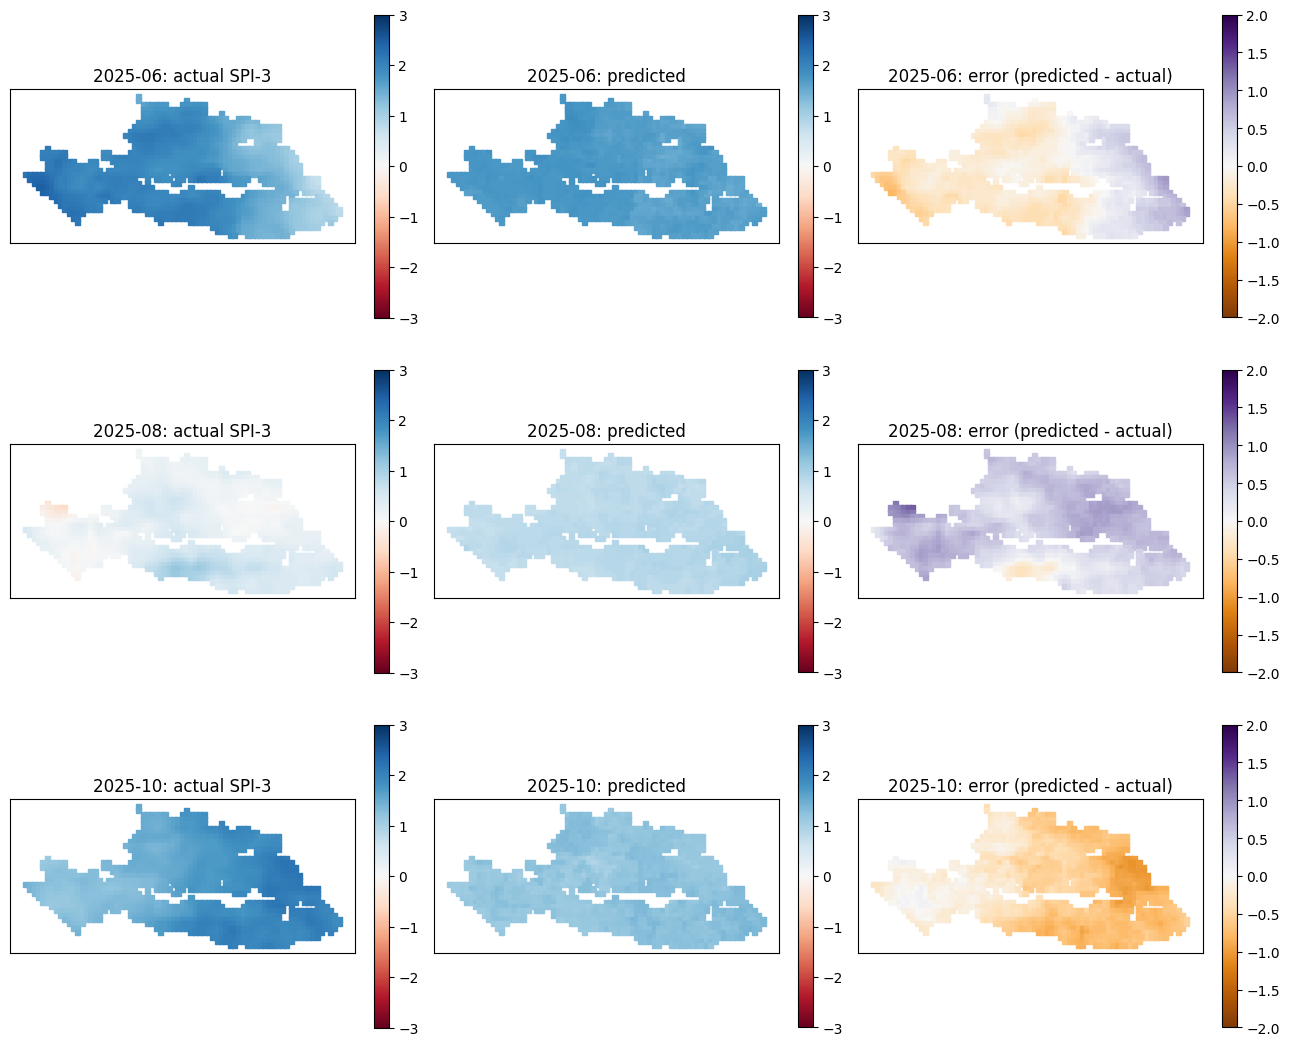

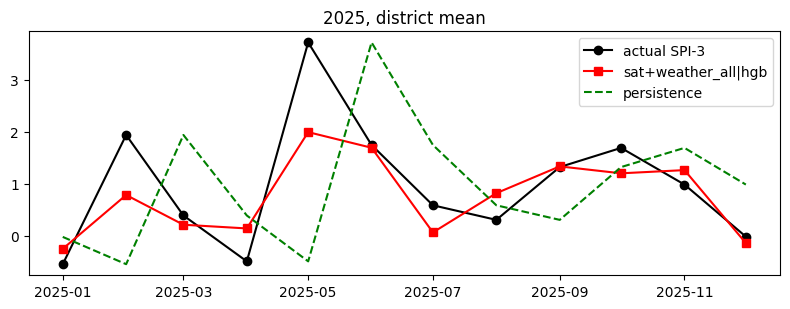

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

BEST = "sat+weather_all|hgb"     # <- replace with the row name chosen from the validation table

# refit on 2020-2024 (climatologies also use 2020-2024), evaluate on 2025
tab_te, preds_te, fit_te, Y_te, base_te, te_t = run_stage(2024, 2025, only=BEST)
print(tab_te[cols].to_string())
tab_te.to_csv(root/'results_test_2025.csv')

P_te = preds_te[BEST]
print("\nconfusion matrix, all patches (rows actual, cols predicted; 0 dry, 1 normal, 2 wet):")
print(confusion_matrix(spi_class(Y_te.ravel()), spi_class(P_te.ravel()), labels=[0, 1, 2]))

# ---- maps: actual vs predicted SPI-3 per patch ----
cx = np.array([lon[c + P // 2] for r, c in origins]); cy = np.array([lat[r + P // 2] for r, c in origins])
show = ['2025-06', '2025-08', '2025-10']
fig, ax = plt.subplots(len(show), 3, figsize=(13, 3.6 * len(show)))
for i, s in enumerate(show):
    j = te_t.index(months.get_loc(pd.Period(s)))
    panels = [('actual SPI-3', Y_te[j], 'RdBu', 3), ('predicted', P_te[j], 'RdBu', 3),
              ('error (predicted - actual)', P_te[j] - Y_te[j], 'PuOr', 2)]
    for a_, (title, v, cm, lim) in zip(ax[i], panels):
        sc = a_.scatter(cx, cy, c=v, s=14, marker='s', cmap=cm, vmin=-lim, vmax=lim)
        a_.set_title(f'{s}: {title}'); a_.set_aspect('equal'); a_.set_xticks([]); a_.set_yticks([])
        plt.colorbar(sc, ax=a_, fraction=0.04)
plt.tight_layout(); plt.savefig(root/'maps_2025.png', dpi=150); plt.show()

# ---- district average through 2025 ----
plt.figure(figsize=(8, 3.2)); x = months[te_t].to_timestamp()
plt.plot(x, Y_te.mean(1), 'k-o', label='actual SPI-3')
plt.plot(x, P_te.mean(1), 'r-s', label=BEST)
plt.plot(x, base_te['persistence'].mean(1), 'g--', label='persistence')
plt.legend(); plt.title('2025, district mean'); plt.tight_layout()
plt.savefig(root/'timeseries_2025.png', dpi=150); plt.show()